# Example of the AiTLAS toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import CITYOSMDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import ResizeToTensor

## Visualize images and masks

Total number of patches: 1671


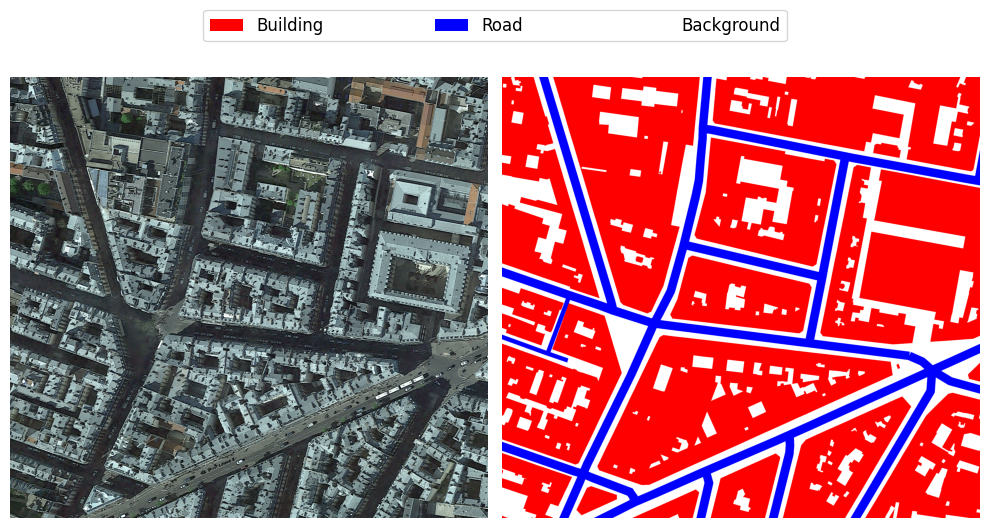

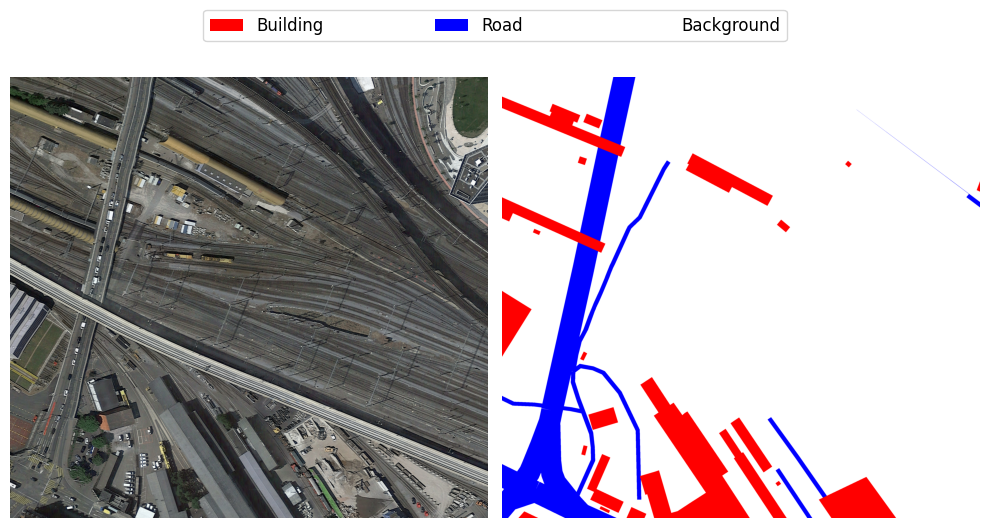

In [4]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/CITY_OSM"
}
dataset = CITYOSMDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(15);

In [5]:
dataset.data_distribution_table()

,Number of pixels
Building,5.145396e+09
Road,2.398128e+09
Background,7.893273e+09


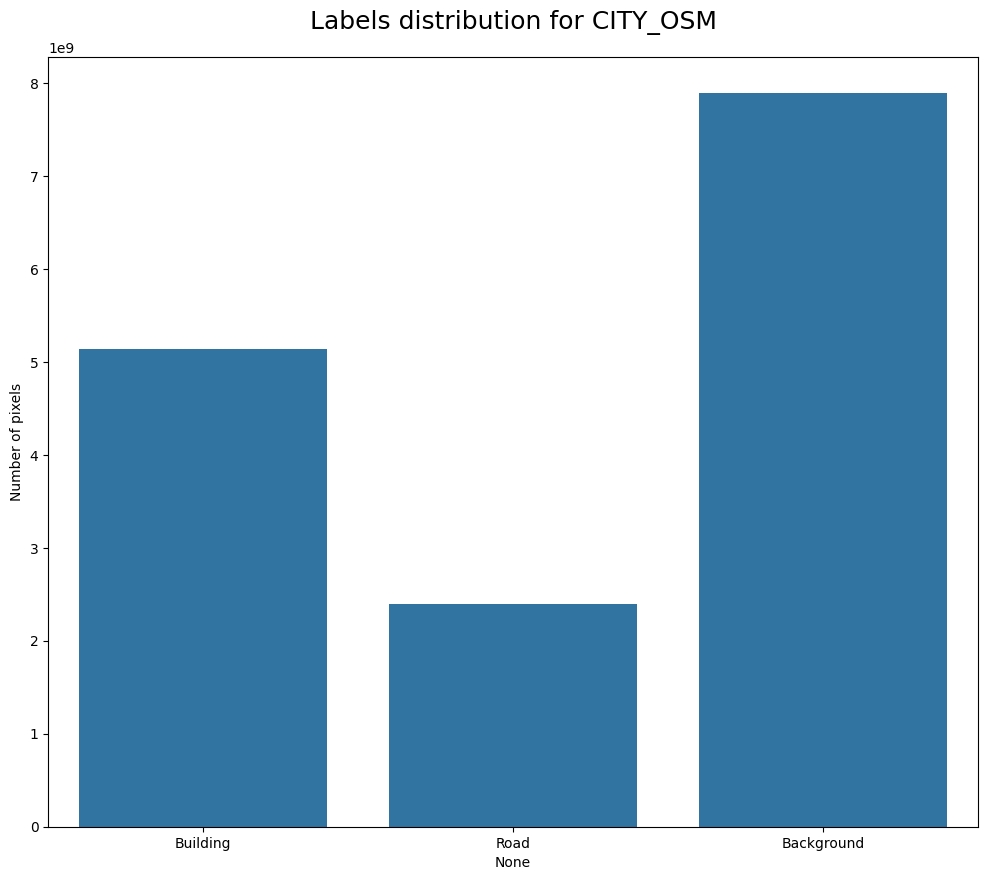

In [6]:
dataset.data_distribution_barchart();

## Load training data

In [4]:
train_dataset_config = {
    "batch_size": 7,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/CITY_OSM",
    "csv_file": "/home/dragik/data/FAIR_EO/CITY_OSM/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = CITYOSMDataset(train_dataset_config)
len(train_dataset)

1337

## Create the model

In [5]:
epochs = 5
model_directory = "/home/dragik/data/FAIR_EO/CITY_OSM"
model_config = {
    "num_classes": 3, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [10]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-27 07:28:24,609 INFO Starting training.
training: 100%|██████████| 191/191 [6:48:06<00:00, 128.20s/it]  
2025-03-27 14:16:31,408 INFO epoch: 1, time: 24487, loss:  0.44901
testing on train set: 100%|██████████| 191/191 [6:45:44<00:00, 127.46s/it]  
2025-03-27 21:02:17,301 INFO IOU:0.45882678066058763, IOU mean:0.43131126110424667, IOU per Class:[0.44034306 0.34722353 0.50636719]
training: 100%|██████████| 191/191 [6:47:14<00:00, 127.93s/it]  
2025-03-28 03:49:31,852 INFO epoch: 2, time: 24434, loss:  0.34494
testing on train set: 100%|██████████| 191/191 [6:41:27<00:00, 126.11s/it]  
2025-03-28 10:30:59,699 INFO IOU:0.5020405328367826, IOU mean:0.4791184005421811, IOU per Class:[0.4969513 0.4119512 0.5284527]
training: 100%|██████████| 191/191 [6:41:48<00:00, 126.22s/it]  
2025-03-28 17:12:47,838 INFO epoch: 3, time: 24108, loss:  0.29970
testing on train set: 100%|██████████| 191/191 [6:44:32<00:00, 127.08s/it]  
2025-03-28 23:57:20,684 INFO IOU:0.5279608757002198, IOU mean:0.

## Evaluate the model

In [11]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/CITY_OSM",
    "csv_file": "/home/dragik/data/FAIR_EO/CITY_OSM/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = CITYOSMDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/CITY_OSM/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

167


2025-03-31 06:42:35,247 INFO Loading checkpoint /home/dragik/data/FAIR_EO/CITY_OSM/checkpoint.pth.tar
2025-03-31 06:42:35,752 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/CITY_OSM/checkpoint.pth.tar at epoch 6
testing on test set: 100%|██████████| 42/42 [55:29<00:00, 79.27s/it]  


[{'IOU': 0.5199188218416957,
  'IOU mean': 0.5017000972668196,
  'IOU per Class': array([0.52349512, 0.43380658, 0.54779859])}]

## Predictions

2025-03-31 08:02:35,973 INFO Loading checkpoint /home/dragik/data/FAIR_EO/CITY_OSM/checkpoint.pth.tar
2025-03-31 08:02:36,569 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/CITY_OSM/checkpoint.pth.tar at epoch 6


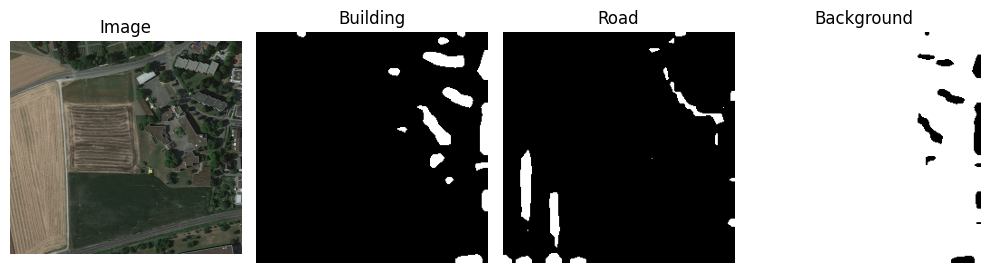

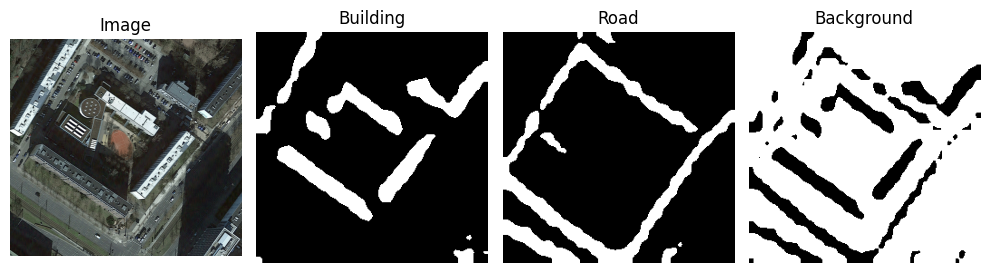

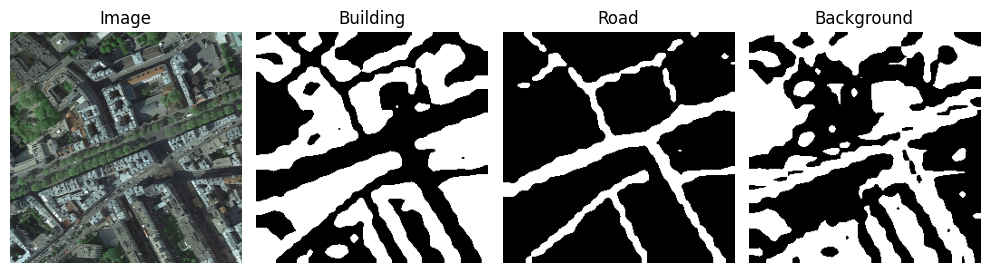

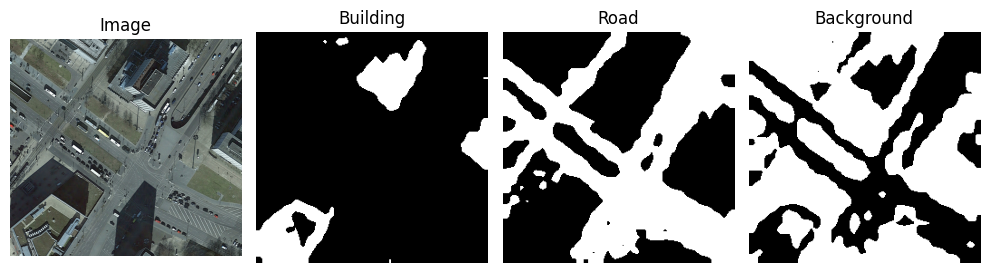

In [6]:
model_path = "/home/dragik/data/FAIR_EO/CITY_OSM/checkpoint.pth.tar"
labels = ["Building","Road","Background"]
transform = ResizeToTensor()
model.load_model(model_path)
csv_file = "/home/dragik/data/FAIR_EO/CITY_OSM/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('/home/dragik/data/FAIR_EO/CITY_OSM/' + test_list[0])
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/CITY_OSM/' + test_list[1])
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/CITY_OSM/' + test_list[10])
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/CITY_OSM/' + test_list[50])
fig = model.predict_masks(image, labels, transform)